<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HecktorGPT2CNSHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 CLASSIFIER
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = [x.copy() for x in (train_df, val_df, test_df)]

# 5. IMPUTE MISSING FEATURES USING TRAINING DATA ONLY
fill_values = {}
for col in FEATURES:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[col].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].astype(str).replace(
                {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
            )

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: n={len(y)}, class counts={np.bincount(y, minlength=2)}")


# 6. CONVERT THE EIGHT CLINICAL FEATURES INTO TEXT PROMPTS

def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()


def format_stage(x, prefix):
    value = display_value(x)

    if value == "Unknown" or value.upper().startswith(prefix):
        return value

    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass

    return f"{prefix}{value}"


def patient_to_text(row):

    age = display_value(row["Age"])
    gender = display_value(row["Gender"])
    tobacco = display_value(row["Tobacco Consumption"])
    alcohol = display_value(row["Alcohol Consumption"])
    performance = display_value(row["Performance Status"])

    t_stage = format_stage(row["T-stage"], "T")
    n_stage = format_stage(row["N-stage"], "N")
    m_stage = format_stage(row["M-stage"], "M")

    return (
        f"This patient is a {age}-year-old {gender}. "
        f"Tobacco consumption is {tobacco}. "
        f"Alcohol consumption is {alcohol}. "
        f"Performance status is {performance}. "
        f"Tumour stage is {t_stage}. "
        f"Nodal stage is {n_stage}. "
        f"Metastatic stage is {m_stage}. "
        "Predict whether the patient is HPV positive or HPV negative."
    )


train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
lengths = [len(tokenizer.encode(t, add_special_tokens=False)) for t in train_texts]
MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))
BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1
print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}

train_ds = HPVTextDataset(train_texts, y_train)
val_ds = HPVTextDataset(val_texts, y_val)
test_ds = HPVTextDataset(test_texts, y_test)
loader_args = {
    "batch_size": BATCH_SIZE, "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze the entire GPT-2 backbone
        for param in self.gpt2.parameters():
            param.requires_grad = False

        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        h = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(h),
            nn.Dropout(DROPOUT),
            nn.Linear(h, 128),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        out = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        ).last_hidden_state

        positions = attention_mask.sum(dim=1) - 1
        pooled = out[
            torch.arange(out.size(0), device=out.device),
            positions
        ]
        return self.classifier(pooled)


model = HPVNetGPT2Text().to(device)

class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Train only the classification head
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels); total += loss.item() * n; n_total += n
    return total / max(n_total, 1)

def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [(float(t), balanced_accuracy_score(labels, scores >= t)) for t in thresholds]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS
from pathlib import Path

OUT_DIR = Path("/content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": float("inf"), "Validation_ROC_AUC": -float("inf"),
    "Validation_PR_AUC": -float("inf"), "Validation_Balanced_Accuracy": -float("inf")
}
best_info, history = {}, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    loss_sum, n_sum = 0.0, 0
    for b in train_loader:
        ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
        labels = b["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = weighted_loss(model(ids, mask), labels)
        loss.backward()
        optimizer.step()
        n = len(labels); loss_sum += loss.item() * n; n_sum += n

    train_loss = loss_sum / max(n_sum, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    threshold, val_ba = choose_threshold(val_scores, val_labels)
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap, "Validation_Balanced_Accuracy": val_ba
    }
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss, **metrics,
        "Validation_Threshold": threshold
    })

    for name, value in metrics.items():
        improved = value < best[name] if name == "Validation_Loss" else value > best[name]
        if improved:
            best[name] = float(value)
            best_info[name] = {"epoch": epoch, "value": float(value), "threshold": threshold}
            torch.save(model.state_dict(), paths[name])

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
              f"Val Loss={val_loss:.4f} | ROC-AUC={val_auc:.4f} | "
              f"PR-AUC={val_ap:.4f} | BA={val_ba:.4f} | Threshold={threshold:.4f}")

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame([
    {"Checkpoint": k, **v, "Path": str(paths[k])} for k, v in best_info.items()
]).to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)

# 12. EVALUATE ALL CHECKPOINTS ON HELD-OUT TEST SET
results, predictions_by_model = [], {}
for name, path in paths.items():
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_scores(test_loader)
    threshold = best_info[name]["threshold"]
    preds = (scores >= threshold).astype(int)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])

    print(f"\n=== {name} | Best epoch {best_info[name]['epoch']} | Threshold {threshold:.4f} ===")
    print(classification_report(
        labels, preds, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"], digits=4, zero_division=0
    ))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(f"Test ROC-AUC={auc:.4f} | PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}")

    results.append({
        "Dataset": "HECKTOR", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": name, "Best_Epoch": best_info[name]["epoch"],
        "Validation_Threshold": threshold, "Test_ROC_AUC": auc,
        "Test_PR_AUC": ap, "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    })
    predictions_by_model[name] = (labels, scores, preds, threshold)
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": preds, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{name.lower()}.csv", index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "65/15/20 stratified", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True, "GPT2_Backbone_Frozen": True,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 1.19MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: n=381, class counts=[ 37 344]
Validation: n=89, class counts=[ 9 80]
Test: n=118, class counts=[ 12 106]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 100226
Trainable parameters: 100226
Epoch 50/500 | Train Loss=0.6867 | Val Loss=0.6946 | ROC-AUC=0.8042 | PR-AUC=0.9727 | BA=0.7701 | Threshold=0.5226
Epoch 100/500 | Train Loss=0.6427 | Val Loss=0.6593 | ROC-AUC=0.8014 | PR-AUC=0.9720 | BA=0.7764 | Threshold=0.4679
Epoch 150/500 | Train Loss=0.6230 | Val Loss=0.6117 | ROC-AUC=0.7944 | PR-AUC=0.9701 | BA=0.7764 | Threshold=0.4975
Epoch 200/500 | Train Loss=0.5623 | Val Loss=0.5856 | ROC-AUC=0.8014 | PR-AUC=0.9726 | BA=0.7701 | Threshold=0.4964
Epoch 250/500 | Train Loss=0.6731 | Val Loss=0.5929 | ROC-AUC=0.7847 | PR-AUC=0.9703 | BA=0.7889 | Threshold=0.3629
Epoch 300/500 | Train Loss=0.5354 | Val Loss=0.5833 | ROC-AUC=0.7833 | PR-AUC=0.9703 | BA=0.7889 | Threshold=0.5110
Epoch 350/500 | Train Loss=0.5514 | Val Loss=0.6007 | ROC-AUC=0.7764 | PR-AUC=0.9690 | BA=0.7764 | Threshold=0.5563
Epoch 400/500 | Train Loss=0.5388 | Val Loss=0.5799 | ROC-AUC=0.7764 | PR-AUC=0.9692 | BA=0.7701 | Threshold=0.4261
Epoch 450/500 |

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
HECKTOR GPT-2 CLASSIFIER — EPOCH 301
Checkpoint: /content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results/best_model_validation_loss.pth
Loaded Validation_Loss checkpoint.
Best epoch: 301

Training data: (381, 8)
Test data: (118, 8)
Test class counts: [ 12 106]

Categorical features:
['Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

Encoded explanation data:
Training: (381, 8)
Test: (118, 8)

Checking GPT-2 prediction function...
Prediction shape: (5, 2)
[[1.0251795e-03 9.9897480e-01]
 [1.4717411e-03 9.9852824e-01]
 [1.2293912e-03 9.9877053e-01]
 [1.5296041e-03 9.9847037e-01]
 [7.1044045e-04 9.9928951e-01]]
GPT-2 prediction function working correctly.

GENERATING SHAP EXPLANATIONS


  0%|          | 0/50 [00:00<?, ?it/s]


SHAP values shape: (50, 8)


/tmp/ipykernel_1722/566873998.py:506: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


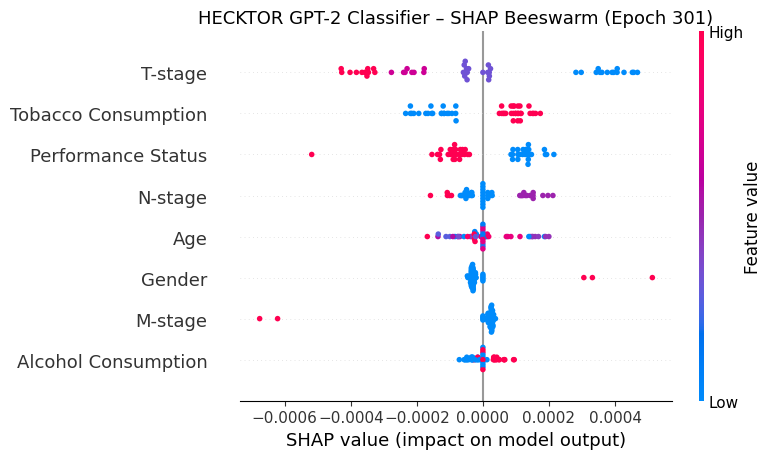


SHAP beeswarm saved: /content/HECKTOR_GPT2_EPOCH301_SHAP_LIME_ROC_PR/HECKTOR_GPT2_Epoch301_SHAP_Beeswarm.png

GENERATING LIME EXPLANATION

LIME explanation for test patient: 0
M-stage=M0: -0.009430
T-stage=T2: -0.002456
Age <= 54.00: -0.002009
Alcohol Consumption=1.0: -0.001756
Gender=1: 0.001538
N-stage=N1: 0.001399
Performance Status=0.0: -0.001281
Tobacco Consumption=1.0: -0.000433


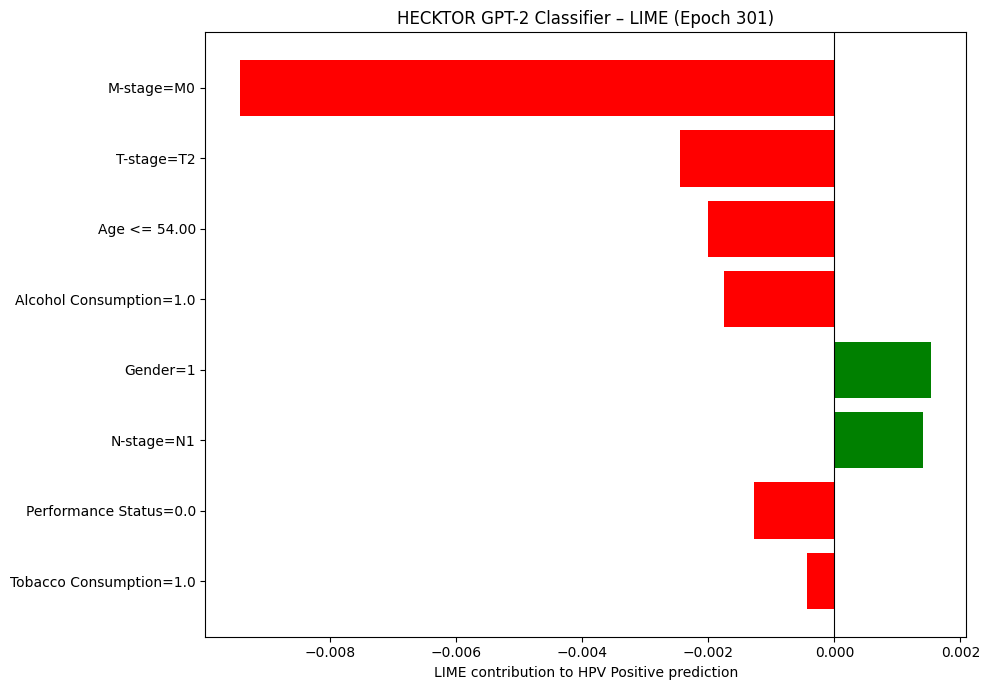


LIME graph saved: /content/HECKTOR_GPT2_EPOCH301_SHAP_LIME_ROC_PR/HECKTOR_GPT2_Epoch301_LIME_Green_Red.png

HECKTOR GPT-2 EPOCH 301 — ROC CURVE POINTS

Test ROC-AUC: 0.734277

(FPR, TPR)
(0.000000, 0.000000),
(0.000000, 0.009434),
(0.000000, 0.141509),
(0.083333, 0.141509),
(0.083333, 0.226415),
(0.166667, 0.226415),
(0.166667, 0.584906),
(0.250000, 0.584906),
(0.250000, 0.594340),
(0.250000, 0.613208),
(0.250000, 0.660377),
(0.333333, 0.660377),
(0.333333, 0.679245),
(0.416667, 0.679245),
(0.416667, 0.688679),
(0.416667, 0.707547),
(0.416667, 0.735849),
(0.500000, 0.735849),
(0.500000, 0.754717),
(0.500000, 0.811321),
(0.500000, 0.830189),
(0.500000, 0.839623),
(0.583333, 0.839623),
(0.583333, 0.971698),
(0.750000, 0.971698),
(0.750000, 1.000000),
(1.000000, 1.000000),

HECKTOR GPT-2 EPOCH 301 — PR CURVE POINTS

Test Average Precision: 0.953254

(Recall, Precision)
(1.000000, 0.898305),
(1.000000, 0.905983),
(1.000000, 0.913793),
(1.000000, 0.921739),
(0.990566, 0.921053),
(0.981132,

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ============================================================
# HECKTOR GPT-2 CLASSIFIER — EPOCH 301
# SHAP BEESWARM + LIME GREEN/RED
# ROC AND PRECISION-RECALL COORDINATES
# SAVE AND DOWNLOAD ALL RESULTS
# ============================================================

%pip -q install shap lime

import os
import zipfile
import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt

from pathlib import Path
from lime.lime_tabular import LimeTabularExplainer

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

from torch.utils.data import DataLoader

from google.colab import files

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

FEATURES = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

OUT_DIR = Path(
    "/content/drive/MyDrive/HECKTOR_GPT2_Discriminative_results"
)

CHECKPOINT_PATH = (
    OUT_DIR / "best_model_validation_loss.pth"
)

OUTPUT_DIR = Path(
    "/content/HECKTOR_GPT2_EPOCH301_SHAP_LIME_ROC_PR"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("HECKTOR GPT-2 CLASSIFIER — EPOCH 301")
print("=" * 70)

# ============================================================
# 2. CHECK REQUIRED NOTEBOOK VARIABLES
# ============================================================

required_variables = [
    "train_df",
    "test_df",
    "patient_to_text",
    "tokenizer",
    "model",
    "device",
    "MAX_LENGTH"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "The following variables are missing. "
        "Run the original GPT-2 training notebook first: "
        + str(missing_variables)
    )

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 301 checkpoint not found: {CHECKPOINT_PATH}"
    )

print("Checkpoint:", CHECKPOINT_PATH)

# ============================================================
# 3. LOAD EPOCH 301 CHECKPOINT
# ============================================================

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )

if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

else:
    state_dict = checkpoint

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("Loaded Validation_Loss checkpoint.")
print("Best epoch: 301")

# ============================================================
# 4. CHECK ORIGINAL DATA
# ============================================================

X_train_original = (
    train_df[FEATURES]
    .copy()
    .reset_index(drop=True)
)

X_test_original = (
    test_df[FEATURES]
    .copy()
    .reset_index(drop=True)
)

y_test = test_df["HPV_Label"].to_numpy(
    dtype=int
)

print("\nTraining data:", X_train_original.shape)
print("Test data:", X_test_original.shape)

print(
    "Test class counts:",
    np.bincount(y_test, minlength=2)
)

# ============================================================
# 5. CREATE CATEGORICAL ENCODINGS
# ============================================================

# All categorical features are treated as nominal.
# No ordinal interpretation is applied.

categorical_features = [
    col
    for col in FEATURES
    if (
        not pd.api.types.is_numeric_dtype(
            X_train_original[col]
        )
        or col in [
            "Gender",
            "Tobacco Consumption",
            "Alcohol Consumption",
            "Performance Status",
            "T-stage",
            "N-stage",
            "M-stage"
        ]
    )
]

categorical_features = [
    col for col in categorical_features
    if col != "Age"
]

categorical_indices = [
    FEATURES.index(col)
    for col in categorical_features
]

category_mappings = {}
category_names = {}

X_train_explain = X_train_original.copy()
X_test_explain = X_test_original.copy()

for col in categorical_features:

    categories = list(
        pd.unique(
            X_train_original[col].astype(str)
        )
    )

    mapping = {
        value: index
        for index, value in enumerate(categories)
    }

    category_mappings[col] = mapping

    idx = FEATURES.index(col)

    category_names[idx] = {
        index: value
        for value, index in mapping.items()
    }

    X_train_explain[col] = (
        X_train_original[col]
        .astype(str)
        .map(mapping)
    )

    X_test_explain[col] = (
        X_test_original[col]
        .astype(str)
        .map(mapping)
    )

# Ensure numeric age
X_train_explain["Age"] = pd.to_numeric(
    X_train_explain["Age"]
)

X_test_explain["Age"] = pd.to_numeric(
    X_test_explain["Age"]
)

X_train_explain = X_train_explain[
    FEATURES
].astype(float)

X_test_explain = X_test_explain[
    FEATURES
].astype(float)

print("\nCategorical features:")
print(categorical_features)

print("\nEncoded explanation data:")
print("Training:", X_train_explain.shape)
print("Test:", X_test_explain.shape)

# ============================================================
# 6. REBUILD GPT-2 PROMPTS FROM ORIGINAL FEATURES
# ============================================================

def decode_explanation_data(X):

    if isinstance(X, pd.DataFrame):
        df = X.copy()
    else:
        df = pd.DataFrame(
            X,
            columns=FEATURES
        )

    df = df[FEATURES].copy()

    for col in categorical_features:

        reverse_mapping = {
            code: value
            for value, code
            in category_mappings[col].items()
        }

        fallback = (
            X_train_original[col]
            .astype(str)
            .mode()
            .iloc[0]
        )

        decoded = []

        for value in df[col].to_numpy():

            code = int(
                np.rint(value)
            )

            decoded.append(
                reverse_mapping.get(
                    code,
                    fallback
                )
            )

        df[col] = decoded

    df["Age"] = pd.to_numeric(
        df["Age"],
        errors="coerce"
    )

    return df


def build_prompts(X):

    decoded = decode_explanation_data(X)

    prompts = [
        patient_to_text(row)
        for _, row in decoded.iterrows()
    ]

    return prompts


# ============================================================
# 7. GPT-2 PREDICTION FUNCTION
# ============================================================

def predict_gpt2_probabilities(X):

    prompts = build_prompts(X)

    model.eval()

    all_probabilities = []

    batch_size = 16

    with torch.no_grad():

        for start in range(
            0,
            len(prompts),
            batch_size
        ):

            batch_prompts = prompts[
                start:start + batch_size
            ]

            encodings = tokenizer(
                batch_prompts,
                max_length=MAX_LENGTH,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )

            input_ids = encodings[
                "input_ids"
            ].to(device)

            attention_mask = encodings[
                "attention_mask"
            ].to(device)

            logits = model(
                input_ids,
                attention_mask
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    return np.asarray(
        all_probabilities
    )


def predict_positive_probability(X):

    return predict_gpt2_probabilities(X)[:, 1]


# Check model predictions
print("\nChecking GPT-2 prediction function...")

check_predictions = predict_gpt2_probabilities(
    X_test_explain.iloc[:5]
)

print("Prediction shape:", check_predictions.shape)
print(check_predictions)

assert check_predictions.shape == (5, 2)

print("GPT-2 prediction function working correctly.")

# ============================================================
# 8. SHAP KERNEL EXPLAINER
# ============================================================

print("\n" + "=" * 70)
print("GENERATING SHAP EXPLANATIONS")
print("=" * 70)

rng = np.random.default_rng(SEED)

background_size = min(
    30,
    len(X_train_explain)
)

explain_size = min(
    50,
    len(X_test_explain)
)

background_indices = rng.choice(
    len(X_train_explain),
    background_size,
    replace=False
)

background = X_train_explain.iloc[
    background_indices
].to_numpy()

X_shap = X_test_explain.iloc[
    :explain_size
].to_numpy()

shap_explainer = shap.KernelExplainer(
    predict_positive_probability,
    background
)

shap_values_raw = shap_explainer.shap_values(
    X_shap,
    nsamples=100,
    silent=False
)

shap_values = np.asarray(
    shap_values_raw
)

# Ensure one SHAP value per patient per original feature
if shap_values.ndim == 3:

    if shap_values.shape[-1] == 1:
        shap_values = shap_values[:, :, 0]

    else:
        shap_values = shap_values[:, :, 0]

shap_values = shap_values.reshape(
    explain_size,
    len(FEATURES)
)

print(
    "\nSHAP values shape:",
    shap_values.shape
)

# ============================================================
# 9. SHAP BEESWARM PLOT
# ============================================================

X_shap_display = X_test_explain.iloc[
    :explain_size
].to_numpy()

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap_display,
    feature_names=FEATURES,
    plot_type="dot",
    show=False
)

plt.title(
    "HECKTOR GPT-2 Classifier – SHAP Beeswarm (Epoch 301)",
    fontsize=13
)

plt.tight_layout()

shap_png = OUTPUT_DIR / (
    "HECKTOR_GPT2_Epoch301_SHAP_Beeswarm.png"
)

plt.savefig(
    shap_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save SHAP values
pd.DataFrame(
    shap_values,
    columns=FEATURES
).to_csv(
    OUTPUT_DIR / "HECKTOR_GPT2_Epoch301_SHAP_Values.csv",
    index=False
)

# Save SHAP display data
pd.DataFrame(
    X_shap_display,
    columns=FEATURES
).to_csv(
    OUTPUT_DIR / "HECKTOR_GPT2_Epoch301_SHAP_Feature_Values.csv",
    index=False
)

print("\nSHAP beeswarm saved:", shap_png)

# ============================================================
# 10. LIME EXPLAINER
# ============================================================

print("\n" + "=" * 70)
print("GENERATING LIME EXPLANATION")
print("=" * 70)

lime_explainer = LimeTabularExplainer(
    training_data=X_train_explain.to_numpy(),
    feature_names=FEATURES,
    categorical_features=categorical_indices,
    categorical_names=category_names,
    mode="classification",
    class_names=[
        "HPV Negative",
        "HPV Positive"
    ],
    discretize_continuous=True,
    random_state=SEED
)

# Explain the first test patient
patient_index = 0

lime_explanation = lime_explainer.explain_instance(
    data_row=X_test_explain.iloc[
        patient_index
    ].to_numpy(),
    predict_fn=predict_gpt2_probabilities,
    num_features=len(FEATURES),
    num_samples=3000
)

lime_contributions = lime_explanation.as_list(
    label=1
)

print(
    "\nLIME explanation for test patient:",
    patient_index
)

for feature, weight in lime_contributions:

    print(
        f"{feature}: {weight:.6f}"
    )

# ============================================================
# 11. LIME GREEN/RED GRAPH
# ============================================================

lime_labels = [
    item[0]
    for item in lime_contributions
]

lime_weights = [
    item[1]
    for item in lime_contributions
]

lime_colours = [
    "green" if weight > 0 else "red"
    for weight in lime_weights
]

fig, ax = plt.subplots(
    figsize=(10, 7)
)

positions = np.arange(
    len(lime_weights)
)

ax.barh(
    positions,
    lime_weights,
    color=lime_colours
)

ax.set_yticks(positions)
ax.set_yticklabels(lime_labels)

ax.axvline(
    0,
    color="black",
    linewidth=0.8
)

ax.set_xlabel(
    "LIME contribution to HPV Positive prediction"
)

ax.set_title(
    "HECKTOR GPT-2 Classifier – LIME (Epoch 301)"
)

ax.invert_yaxis()

plt.tight_layout()

lime_png = OUTPUT_DIR / (
    "HECKTOR_GPT2_Epoch301_LIME_Green_Red.png"
)

plt.savefig(
    lime_png,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Save LIME values
pd.DataFrame(
    lime_contributions,
    columns=[
        "Feature",
        "LIME_Contribution"
    ]
).to_csv(
    OUTPUT_DIR / "HECKTOR_GPT2_Epoch301_LIME_Values.csv",
    index=False
)

print("\nLIME graph saved:", lime_png)

# ============================================================
# 12. ROC CURVE COORDINATES
# ============================================================

print("\n" + "=" * 70)
print("HECKTOR GPT-2 EPOCH 301 — ROC CURVE POINTS")
print("=" * 70)

# Obtain probabilities for the complete held-out test set
test_probabilities = predict_positive_probability(
    X_test_explain
)

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

print(
    f"\nTest ROC-AUC: {roc_auc:.6f}"
)

print("\n(FPR, TPR)")

for x, y in zip(fpr, tpr):

    print(
        f"({x:.6f}, {y:.6f}),"
    )

# Save ROC points
pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": roc_thresholds
}).to_csv(
    OUTPUT_DIR / "HECKTOR_GPT2_Epoch301_ROC_Points.csv",
    index=False
)

# ============================================================
# 13. PRECISION-RECALL CURVE COORDINATES
# ============================================================

print("\n" + "=" * 70)
print("HECKTOR GPT-2 EPOCH 301 — PR CURVE POINTS")
print("=" * 70)

precision, recall, pr_thresholds = (
    precision_recall_curve(
        y_test,
        test_probabilities
    )
)

pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

print(
    f"\nTest Average Precision: {pr_auc:.6f}"
)

print("\n(Recall, Precision)")

for x, y in zip(recall, precision):

    print(
        f"({x:.6f}, {y:.6f}),"
    )

# Save PR points
pd.DataFrame({
    "Recall": recall,
    "Precision": precision
}).to_csv(
    OUTPUT_DIR / "HECKTOR_GPT2_Epoch301_PR_Points.csv",
    index=False
)

# ============================================================
# 14. SAVE TEST PREDICTIONS
# ============================================================

pd.DataFrame({
    "True_Label": y_test,
    "HPV_Positive_Probability": test_probabilities
}).to_csv(
    OUTPUT_DIR / "HECKTOR_GPT2_Epoch301_Test_Predictions.csv",
    index=False
)

# ============================================================
# 15. SAVE SUMMARY METRICS
# ============================================================

summary = pd.DataFrame({
    "Metric": [
        "Checkpoint",
        "Best Epoch",
        "Test ROC-AUC",
        "Test PR-AUC",
        "Test Observations",
        "SHAP Observations",
        "SHAP Background Observations",
        "LIME Patient Index"
    ],
    "Value": [
        "Validation_Loss",
        301,
        roc_auc,
        pr_auc,
        len(y_test),
        explain_size,
        background_size,
        patient_index
    ]
})

summary.to_csv(
    OUTPUT_DIR / "HECKTOR_GPT2_Epoch301_Summary.csv",
    index=False
)

print("\nSUMMARY:")
print(summary.to_string(index=False))

# ============================================================
# 16. CREATE DOWNLOADABLE ZIP
# ============================================================

zip_path = Path(
    "/content/HECKTOR_GPT2_Epoch301_SHAP_LIME_ROC_PR.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file_path in sorted(
        OUTPUT_DIR.iterdir()
    ):

        if file_path.is_file():

            zipf.write(
                file_path,
                arcname=file_path.name
            )

# ============================================================
# 17. VERIFY ALL OUTPUT FILES
# ============================================================

print("\n" + "=" * 70)
print("GENERATED FILES")
print("=" * 70)

for file_path in sorted(
    OUTPUT_DIR.iterdir()
):

    if file_path.is_file():

        print(
            file_path.name,
            "-",
            round(
                file_path.stat().st_size / 1024,
                2
            ),
            "KB"
        )

print("\nZIP created:", zip_path)

# ============================================================
# 18. DOWNLOAD ALL RESULTS
# ============================================================

print("\nDownloading all epoch 301 results...")

files.download(
    str(zip_path)
)